# Three- and four-population V1 models: dispersion with the report coefficients

This notebook uses **the same coefficients as `final_report/main.tex` (Sections 7–9),
`analysis.ipynb` and `analysis_2d.ipynb`**, all read from `simulations/v1_literature.py`.
The earlier integer-gain example (`v1_simple.py`, $L=20$, gain 4, threshold 1/4)
is no longer used here.

| quantity | value |
|---|---|
| populations | E, PV, SST, VIP (rows = targets, columns = sources) |
| $G$ | report eq. (v1-gain-matrices); three-population model = E/PV/SST block with **E→E strengthened 6.22009 → 6.72 (+8.04%)**, all other entries unchanged |
| widths | Billeh et al. (2020) scales $s_{ij}$; $\Sigma_{ij}=(s_{ij}/100\,\mu\text{m})^2/2$ |
| $\tau$ | $(10,12,35,20)$ ms |
| sigmoid gain $g$ | $(3.47682761,\,7.34413013,\,3.74650527,\,6)$ |
| threshold $\theta$ | $(0.28483799,\,0.12068148,\,0.40137356,\,0.7)$ |
| domain | $L=43$ model units $=4.3$ mm (one unit $=0.1$ mm) |
| input | $e=(1,1,0,0)^{\mathsf T}$ (E and PV) |

$J=\kappa G$. For each model, $\kappa$ is increased from 0 to its own first instability
$\kappa_c$, and the dispersion relation is evaluated there:
$$M(q,\kappa)=D_\tau^{-1}\big[-I+(\kappa G\odot e^{-\Sigma q^2/2})D_F\big],\qquad
\det(\nu I-M)=0,\quad \nu=\sigma+i\omega .$$
Wavenumbers are shown in physical units, $q_{\rm phys}=10\,q$ rad/mm, and frequencies as
$f=\omega/2\pi$ in Hz. The torus only admits $q_k=2\pi k/L$ (dots); the continuous curves
interpolate them.

**Three-population gains.** Deleting VIP without changing any gain gives a **homogeneous**
($k=0$) first Hopf crossing at $\kappa\approx0.65373$, as stated in the report. Strengthening E→E
by 8.04% (widths, signs and zeros unchanged) moves the first crossing to $k_0=3$, like the
four-population model. This is the three-population model used here and in `analysis.ipynb`
(Section 7). Its onset $\kappa_c$ is **recomputed** by the same sweep as for four populations.
The unmodified block is drawn as a thin gray reference curve in the main figure.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig
from scipy.optimize import brentq
from scipy.special import expit
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'simulations/v1_literature.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from simulations.v1_literature import make_model, coefficients, audit, S_UM
from simulations.fft import linear_symbol, compute_bifurcation
from simulations.simulation import activation_derivatives

OUT = ROOT/'simulations/output/v1_three_four_literature'
OUT.mkdir(parents=True, exist_ok=True)
EPS = .02
COLORS = {3: 'C1', 4: 'C0'}

models, onset = {}, {}
for K in (3, 4):
    model = make_model(K)
    cr = compute_bifurcation(model, p_bounds=(0, 1), max_mode=64, scan_points=101)
    models[K], onset[K] = model, cr
    print(f'{K} populations {model.names}')
    print('  G =\n', model.A_p)
    print('  Sigma (0.1 mm)^2 =\n', np.where(model.A_p != 0, model.Sigma, np.nan).round(5))
    print('  tau (ms):', model.tau, ' g:', model.gain, ' theta:', model.theta)
    print(f'  first onset: kappa_c = {cr.p0:.10f}, mode k = {cr.mode}, '
          f'q = {10*cr.q:.4f} rad/mm, f = {cr.frequency_hz:.6f} Hz\n')

3 populations ('E', 'PV', 'SST')
  G =
 [[ 6.72    -1.45455 -6.48944]
 [ 5.09798 -0.90615 -8.04066]
 [ 2.67174  0.       0.     ]]
  Sigma (0.1 mm)^2 =
 [[0.6498  0.45125 0.36125]
 [0.4232  0.72    0.72   ]
 [0.53045     nan     nan]]
  tau (ms): [10. 12. 35.]  g: [3.47682761 7.34413013 3.74650527]  theta: [0.28483799 0.12068148 0.40137356]
  first onset: kappa_c = 0.5880341657, mode k = 3, q = 4.3836 rad/mm, f = 9.540771 Hz

4 populations ('E', 'PV', 'SST', 'VIP')
  G =
 [[  6.22009  -1.45455  -6.48944   0.     ]
 [  5.09798  -0.90615  -8.04066   0.     ]
 [  2.67174   0.        0.      -16.     ]
 [  1.68844   0.       -3.13584   0.     ]]
  Sigma (0.1 mm)^2 =
 [[0.6498  0.45125 0.36125     nan]
 [0.4232  0.72    0.72        nan]
 [0.53045     nan     nan 0.72   ]
 [0.53045     nan 0.72        nan]]
  tau (ms): [10. 12. 35. 20.]  g: [3.47682761 7.34413013 3.74650527 6.        ]  theta: [0.28483799 0.12068148 0.40137356 0.7       ]
  first onset: kappa_c = 0.7491489065, mode k = 3, q 

## 1. Normal-form coefficients

Four populations: recomputed from the model and checked against the values printed in the report.
Three populations: recomputed at the new onset with the same code; `model_audit` checks the 1D
torus modes, cubic stability and the forcing thresholds used in `analysis.ipynb`.

In [2]:
m4 = models[4]
critical, normal, extra = coefficients(m4)
checks = audit(m4, critical, normal, extra)
print('kappa_c =', critical.p0, ' k0 =', critical.mode, ' omega0 =', critical.omega0, 'rad/ms')
print('alpha =', normal.alpha, '\nb =', normal.b, '\nc =', normal.c)
print('eta_t^(1) =', extra['eta_t_unit'], '\neta_x^(1) =', extra['eta_x_unit'])
print('d omega/dq at q0 =', extra['nu_q'].imag, '(model units) =', .1*extra['nu_q'].imag, 'mm/ms')
report = dict(kappa=.7491489065, omega=.0829864799, alpha=.0880577+.0643807j,
              b=-6.706479+9.069454j, c=-6.961796+8.999612j,
              eta_t=.055509-.029075j, eta_x=.018902+.046191j, slope=.0471593)
assert critical.mode == 3 and abs(critical.p0-report['kappa']) < 1e-9
assert abs(critical.omega0-report['omega']) < 1e-9
for key, value in [('alpha', normal.alpha), ('b', normal.b), ('c', normal.c),
                   ('eta_t', extra['eta_t_unit']), ('eta_x', extra['eta_x_unit'])]:
    assert abs(value-report[key]) < 5e-6*max(1, abs(report[key])), key
assert abs(extra['nu_q'].imag-report['slope']) < 1e-6
print('\nAll four-population values agree with final_report/main.tex.')

from simulations.main_analysis import model_audit
m3 = models[3]
critical3, normal3, extra3 = coefficients(m3)
checks3 = model_audit(3, m3, critical3, normal3, extra3)
print('\nThree populations: kappa_c =', critical3.p0, ' k0 =', critical3.mode, ' f0 =', critical3.frequency_hz, 'Hz')
print('alpha =', normal3.alpha, '\nb =', normal3.b, '\nc =', normal3.c)
print('eta_t^(1) =', extra3['eta_t_unit'], '\neta_x^(1) =', extra3['eta_x_unit'])
print('d omega/dq at q0 =', extra3['nu_q'].imag, '(model units) =', .1*extra3['nu_q'].imag, 'mm/ms')
print('thresholds: temporal', checks3['temporal_threshold'], ' spatial', checks3['spatial_threshold'],
      ' (spatial branch sign', checks3['spatial_branch_sign'], ')')
assert critical3.mode == 3 and extra3['nu_q'].imag > 0

kappa_c = 0.7491489064741298  k0 = 3  omega0 = 0.08298647990840823 rad/ms
alpha = (0.08805771699823847+0.06438068242546048j) 
b = (-6.706478568714678+9.069453518448277j) 
c = (-6.961796349310244+8.99961232093737j)
eta_t^(1) = (0.055508504933447216-0.02907492796093994j) 
eta_x^(1) = (0.01890211615952511+0.04619147682959991j)
d omega/dq at q0 = 0.04715929643439774 (model units) = 0.004715929643439774 mm/ms

All four-population values agree with final_report/main.tex.

Three populations: kappa_c = 0.5880341656628892  k0 = 3  f0 = 9.540770728482336 Hz
alpha = (0.08665736136649406+0.03560858901401072j) 
b = (-3.4125551322511196+1.8288718196158835j) 
c = (-3.4056279476070865+1.67304155589894j)
eta_t^(1) = (0.038522686198754666-0.048663171711349054j) 
eta_x^(1) = (-0.003255047151742401+0.054558002734123985j)
d omega/dq at q0 = 0.040498824816442396 (model units) = 0.0040498824816442396 mm/ms
thresholds: temporal 1.5095093441141683  spatial 26.622459622468774  (spatial branch sign -1.0 )


## 2. Dispersion tools

For a simple eigenvalue with right/left eigenvectors $Mv=\nu v$, $w^*M=\nu w^*$, $w^*v=1$
(report eq. dispersion-derivatives),
$$\nu_q=w^*M_qv,\qquad M_q=-qD_\tau^{-1}\big[(\Sigma\odot\widehat W(q))D_F\big],
\qquad \omega_q=\operatorname{Im}\nu_q .$$
For both models $M(q)$ has **at most one complex-conjugate pair** at every $q$ (checked below),
so the oscillatory branch $\omega_{\rm pair}(q)$ is unambiguous until the pair collides on the
real axis. The **rightmost** frequency $\omega_{\rm r}(q)$ (report eq. rightmost-frequency) equals
$\omega_{\rm pair}$ where the pair is dominant and $0$ where a real eigenvalue is rightmost.

In [3]:
def D_F(model):
    return activation_derivatives(model)[0]

def spectrum(model, q, kappa):
    return np.linalg.eigvals(linear_symbol(model, q, kappa))

def pair(model, q, kappa):
    'Eigenvalue of the complex pair with Im > 0 (nan once it has become real).'
    ev = spectrum(model, q, kappa); c = ev[ev.imag > 1e-10]
    assert len(c) <= 1, 'more than one complex pair'
    return c[0] if len(c) else complex(np.nan, np.nan)

def rightmost(model, q, kappa):
    ev = spectrum(model, q, kappa)
    top = ev[np.isclose(ev.real, ev.real.max(), atol=1e-12, rtol=0)]
    return top[np.argmax(top.imag)]

def pair_slope(model, q, kappa):
    'Analytic nu_q = w* M_q v / w* v for the complex pair.'
    M = linear_symbol(model, q, kappa)
    vals, left, right = eig(M, left=True, right=True)
    target = pair(model, q, kappa)
    if np.isnan(target.real): return complex(np.nan, np.nan)
    j = np.argmin(abs(vals-target))
    What = model.connectivity(kappa)*np.exp(-model.Sigma*q*q/2)
    Mq = -q*(model.Sigma*What*D_F(model)[None, :])/model.tau[:, None]
    return np.vdot(left[:, j], Mq@right[:, j])/np.vdot(left[:, j], right[:, j])

def hz(omega): return np.asarray(omega)*1000/(2*np.pi)

qs = np.linspace(0, 4.5, 1801)        # model units; x10 gives rad/mm
disp = {}
for K, model in models.items():
    kc = onset[K].p0
    P = np.array([pair(model, q, kc) for q in qs])
    R = np.array([rightmost(model, q, kc) for q in qs])
    S = np.array([pair_slope(model, q, kc) for q in qs])
    allev = np.array([np.sort_complex(spectrum(model, q, kc)) for q in qs])
    real_max = np.array([max([z.real for z in spectrum(model, q, kc) if abs(z.imag) < 1e-10], default=np.nan) for q in qs])
    alive = ~np.isnan(P.real)
    q_collide = qs[np.argmax(~alive)] if (~alive).any() else np.nan
    sl = np.where(alive & (qs > .01), S.imag, np.nan)
    zero = np.flatnonzero((sl[:-1] > 0) & (sl[1:] <= 0))   # + to - : frequency maximum
    q_peak = brentq(lambda q: pair_slope(model, q, kc).imag, qs[zero[0]], qs[zero[0]+1]) if len(zero) else np.nan
    dominant = alive & (P.real >= np.nan_to_num(real_max, nan=-np.inf))
    disp[K] = dict(P=P, R=R, S=S, allev=allev, real_max=real_max, alive=alive, dominant=dominant,
                   q_collide=q_collide, q_peak=q_peak, f_peak=hz(pair(model, q_peak, kc).imag))
    print(f'{K} pop: pair exists for q < {10*q_collide:.2f} rad/mm; '
          f'frequency maximum {disp[K]["f_peak"]:.4f} Hz at q = {10*q_peak:.4f} rad/mm '
          f'(d omega/dq = 0 there); pair is rightmost on '
          f'{100*dominant[alive].mean():.1f}% of its q range')

3 pop: pair exists for q < 37.70 rad/mm; frequency maximum 12.4141 Hz at q = 11.7207 rad/mm (d omega/dq = 0 there); pair is rightmost on 44.1% of its q range
4 pop: pair exists for q < 38.98 rad/mm; frequency maximum 16.4347 Hz at q = 11.4385 rad/mm (d omega/dq = 0 there); pair is rightmost on 28.6% of its q range


## 3. Frequency versus wave number

**Main figure.** Frequency of the oscillatory branch at each model's own onset $\kappa_c$.
Solid: the pair is the rightmost eigenvalue; dashed: the pair still exists but a real eigenvalue
is to its right (there $\omega_{\rm r}=0$). Dots are the admissible torus modes $k=0,1,2,\dots$;
the ring marks the critical mode, the star the frequency maximum.

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.2), layout='constrained')
for K, d in disp.items():
    model, cr = models[K], onset[K]
    f = hz(d['P'].imag)
    solid = np.where(d['dominant'], f, np.nan); dashed = np.where(d['alive'], f, np.nan)
    ax.plot(10*qs, dashed, ls='--', color=COLORS[K], lw=1, alpha=.7)
    ax.plot(10*qs, solid, color=COLORS[K], lw=2.2, label=f'{K} populations ({"/".join(model.names)}{", E→E +8.04%" if K == 3 else ""}), κ = κc = {cr.p0:.4f}')
    ks = np.arange(0, int(4.5*model.length/(2*np.pi))+1); qk = 2*np.pi*ks/model.length
    fk = hz([pair(model, q, cr.p0).imag for q in qk])
    ax.scatter(10*qk, fk, s=18, color=COLORS[K], zorder=4)
    ax.scatter(10*cr.q, cr.frequency_hz, s=140, facecolor='none', edgecolor='k', lw=1.5, zorder=5)
    ax.annotate(f'critical k={cr.mode}\n{cr.frequency_hz:.3f} Hz', (10*cr.q, cr.frequency_hz),
                xytext=(12, -30) if K == 3 else (14, -24), textcoords='offset points', fontsize=8)
    ax.scatter(10*d['q_peak'], d['f_peak'], marker='*', s=150, color=COLORS[K], edgecolor='k', zorder=6)
    ax.axvline(10*d['q_collide'], color=COLORS[K], ls=':', lw=1)
ref = make_model(3, submatrix=True)
ref_cr = compute_bifurcation(ref, p_bounds=(0, 1), max_mode=64, scan_points=101)
ax.plot(10*qs, hz([pair(ref, q, ref_cr.p0).imag for q in qs]), color='.55', lw=1,
        label=f'3 populations, unmodified block (k=0 onset, κc = {ref_cr.p0:.4f}); reference')
ax.set(xlabel='wavenumber q (rad/mm)', ylabel='frequency f = ω/2π (Hz)',
       title='Dispersion curve: frequency vs wavenumber at onset (report coefficients, L = 4.3 mm)',
       xlim=(0, 45), ylim=(0, None))
ax.plot([], [], 'k--', lw=1, label='pair not rightmost (ω_r = 0 there)')
ax.plot([], [], 'k:', lw=1, label='pair collides on real axis')
ax.legend(fontsize=8, loc='lower left'); ax.grid(alpha=.25)
fig.savefig(OUT/'frequency_vs_wavenumber.png', dpi=160); plt.show()

/var/folders/tx/tfsy16mx3gd38p3pdnv9vj4m0000gn/T/ipykernel_77353/2861325398.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(OUT/'frequency_vs_wavenumber.png', dpi=160); plt.show()


**Full spectra.** Columns: growth rate of every branch (gray) and the rightmost eigenvalue;
frequency of every branch with $\operatorname{Im}\nu\ge0$ and the rightmost frequency $\omega_{\rm r}$
(it drops to 0 where a real eigenvalue becomes rightmost); analytic slope $d\omega/dq$ of the complex pair,
in mm/ms as in the report (positive = frequency increases with wavenumber; the slope diverges where the pair collides on the real axis, outside the plotted range).

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for row, (K, d) in enumerate(disp.items()):
    model, cr = models[K], onset[K]
    axs[row, 0].scatter(np.repeat(10*qs, K)[::3], d['allev'].real.ravel()[::3], s=.3, color='.6', label='all eigenvalues')
    axs[row, 0].plot(10*qs, d['P'].real, color='.35', lw=.8, ls='--', label='complex pair')
    axs[row, 1].plot(10*qs, hz(d['P'].imag), color='.55', lw=1, ls='--', label='complex pair (also when subdominant)')
    axs[row, 0].plot(10*qs, d['R'].real, color=COLORS[K], lw=2, label='rightmost')
    fr = hz(np.maximum(d['R'].imag, 0)); jumps = np.flatnonzero(abs(np.diff(fr)) > .5)
    fr[jumps+1] = np.nan
    axs[row, 1].plot(10*qs, fr, color=COLORS[K], lw=2, label='rightmost ω_r/2π')
    slope = .1*d['S'].imag
    axs[row, 2].plot(10*qs, slope, color=COLORS[K], lw=2)
    axs[row, 2].fill_between(10*qs, 0, slope, where=slope > 0, color=COLORS[K], alpha=.15, label='frequency increasing')
    axs[row, 2].axhline(0, color='k', lw=.6)
    axs[row, 2].scatter(10*cr.q, .1*pair_slope(model, cr.q, cr.p0).imag, color='k', zorder=5, label=f'critical q: {.1*pair_slope(model, cr.q, cr.p0).imag:.6f} mm/ms')
    axs[row, 0].axhline(0, color='k', lw=.6); axs[row, 0].set(ylim=(-.06, .004)); axs[row, 2].set(ylim=(-.007, .006))
    for ax in axs[row]:
        ax.axvline(10*cr.q, color='k', ls='--', lw=.8); ax.set(xlabel='wavenumber q (rad/mm)', xlim=(0, 45)); ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    axs[row, 0].set(ylabel='growth Re ν (1/ms)', title=f'{K} populations: growth, κ = κc = {cr.p0:.5f}')
    axs[row, 1].set(ylabel='frequency (Hz)', title=f'{K} populations: frequency of every branch')
    axs[row, 2].set(ylabel='dω/dq (mm/ms)', title=f'{K} populations: slope of the complex pair')
fig.savefig(OUT/'dispersion_full_spectrum.png', dpi=150); plt.show()

/var/folders/tx/tfsy16mx3gd38p3pdnv9vj4m0000gn/T/ipykernel_77353/435352751.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(OUT/'dispersion_full_spectrum.png', dpi=150); plt.show()


## 4. Discrete torus modes

Rightmost growth and frequency for the admissible modes $q_k=2\pi k/43$ (model units).
For four populations, the rows $k=0,\dots,4$ reproduce the report values
$11.0865,\,11.3759,\,12.1588,\,13.2077,\,14.2833$ Hz.

In [6]:
rows = {}
for K, model in models.items():
    cr = onset[K]; rows[K] = []
    print(f'\n{K} populations (kappa = kappa_c = {cr.p0:.8f})')
    print(' k   q (rad/mm)   Re nu_r (1/ms)   f_r (Hz)   f_pair (Hz)   dω/dq (mm/ms)')
    for k in range(13):
        q = 2*np.pi*k/model.length; r = rightmost(model, q, cr.p0); p = pair(model, q, cr.p0)
        s = .1*pair_slope(model, q, cr.p0).imag
        rows[K].append(dict(k=k, q_rad_per_mm=10*q, growth=r.real, f_rightmost_hz=float(hz(max(r.imag, 0))),
                            f_pair_hz=float(hz(p.imag)), domega_dq_mm_per_ms=s))
        print(f'{k:2d} {10*q:11.4f} {r.real:15.3e} {hz(max(r.imag,0)):10.4f} {hz(p.imag):12.4f} {s:14.6f}')
expected = [11.0865, 11.3759, 12.1588, 13.2077, 14.2833]
assert np.allclose([rows[4][k]['f_rightmost_hz'] for k in range(5)], expected, atol=6e-5)
print('\nFour-population rightmost frequencies for k = 0..4 match the report.')
(OUT/'discrete_modes.json').write_text(json.dumps(rows, indent=2))


3 populations (kappa = kappa_c = 0.58803417)
 k   q (rad/mm)   Re nu_r (1/ms)   f_r (Hz)   f_pair (Hz)   dω/dq (mm/ms)
 0      0.0000      -2.364e-03     7.7838       7.7838       0.000000
 1      1.4612      -1.597e-03     8.0064       8.0064       0.001913
 2      2.9224      -2.784e-04     8.6473       8.6473       0.003468
 3      4.3836       1.958e-15     9.5408       9.5408       0.004050
 4      5.8448      -1.372e-03    10.4677      10.4677       0.003819
 5      7.3060      -4.312e-03    11.2811      11.2811       0.003120
 6      8.7672      -8.555e-03    11.8998      11.8998       0.002172
 7     10.2284      -1.381e-02    12.2826      12.2826       0.001110
 8     11.6896      -1.978e-02    12.4140      12.4140       0.000023
 9     13.1509      -2.621e-02    12.2967      12.2967      -0.001019
10     14.6121      -3.288e-02    11.9475      11.9475      -0.001964
11     16.0733      -3.959e-02    11.3939      11.3939      -0.002771
12     17.5345      -4.189e-02     0.000

6144

## 5. Dispersion near onset for $p=\kappa-\kappa_c\in\{-2,\dots,2\}\epsilon^2$

$\epsilon=0.02$ as in the forcing runs. Changing $p$ by $O(\epsilon^2)$ barely moves the frequency curve;
the sign of $d\omega/dq$ at the critical wave number is robust.

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), layout='constrained')
qn = np.linspace(0, 2, 401)
for ax, (K, model) in zip(axs, models.items()):
    cr = onset[K]
    for p in [-2, -1, 0, 1, 2]:
        kappa = cr.p0+p*EPS**2
        ax.plot(10*qn, hz([pair(model, q, kappa).imag for q in qn]), label=f'p = {p}ε²', lw=1.2)
    qk = 2*np.pi*np.arange(15)/model.length; qk = qk[qk <= 2]
    ax.scatter(10*qk, hz([pair(model, q, cr.p0).imag for q in qk]), color='k', s=12, zorder=5, label='torus modes, p = 0')
    ax.axvline(10*cr.q, color='k', ls='--', lw=.8)
    ax.set(xlabel='wavenumber q (rad/mm)', ylabel='pair frequency (Hz)', title=f'{K} populations near onset'); ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.savefig(OUT/'frequency_near_onset.png', dpi=150); plt.show()

/var/folders/tx/tfsy16mx3gd38p3pdnv9vj4m0000gn/T/ipykernel_77353/4026428174.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(OUT/'frequency_near_onset.png', dpi=150); plt.show()


## 6. Marginal-stability (neutral) dispersion

A second view of the same relation: for each wavenumber $q$, raise $\kappa$ until the
complex pair at that $q$ crosses $\operatorname{Re}\nu=0$. This gives the neutral gain
$\kappa_H(q)$ and the Hopf frequency $\omega_H(q)$ that a pattern **at that wavenumber** would have
at its own onset. The minimum of $\kappa_H$ over admissible modes is the first instability.

In [8]:
def neutral(model, q, kmax=3., n=121):
    grid = np.linspace(0, kmax, n)
    g = np.array([pair(model, q, k).real for k in grid])
    idx = np.flatnonzero((g[:-1] < 0) & (g[1:] >= 0))
    if not len(idx): return np.nan, np.nan
    k = brentq(lambda k: pair(model, q, k).real, grid[idx[0]], grid[idx[0]+1], xtol=1e-12)
    return k, pair(model, q, k).imag

qh = np.linspace(0, 2.2, 221)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), layout='constrained')
for K, model in models.items():
    kh, wh = np.array([neutral(model, q) for q in qh]).T
    axs[0].plot(10*qh, kh, color=COLORS[K], label=f'{K} populations')
    axs[1].plot(10*qh, hz(wh), color=COLORS[K], label=f'{K} populations')
    qk = 2*np.pi*np.arange(16)/model.length; qk = qk[qk <= 2.2]
    kk, wk = np.array([neutral(model, q) for q in qk]).T
    axs[0].scatter(10*qk, kk, color=COLORS[K], s=14); axs[1].scatter(10*qk, hz(wk), color=COLORS[K], s=14)
    i = np.nanargmin(kk)
    axs[0].scatter(10*qk[i], kk[i], s=140, facecolor='none', edgecolor='k', zorder=5)
    print(f'{K} pop: min neutral kappa over torus modes = {kk[i]:.10f} at k = {i}')
axs[0].set(xlabel='wavenumber q (rad/mm)', ylabel='neutral gain κ_H(q)', title='Hopf neutral curve (ring: first instability)')
axs[1].set(xlabel='wavenumber q (rad/mm)', ylabel='Hopf frequency ω_H/2π (Hz)', title='Frequency on the neutral curve')
for ax in axs: ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.savefig(OUT/'neutral_dispersion.png', dpi=150); plt.show()

3 pop: min neutral kappa over torus modes = 0.5880341657 at k = 3
4 pop: min neutral kappa over torus modes = 0.7491489065 at k = 3


/var/folders/tx/tfsy16mx3gd38p3pdnv9vj4m0000gn/T/ipykernel_77353/3487838323.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(OUT/'neutral_dispersion.png', dpi=150); plt.show()


## 7. Checks

1. The analytic slope $\operatorname{Im}(w^*M_qv)$ agrees with a centred finite difference of $\omega_{\rm pair}(q)$.
2. **Direct field check.** The full nonlinear field (FFT convolution, RK4, $\Delta t=0.5$ ms, $N=64$)
   is started, separately for each torus mode $k$, from a tiny traveling eigenmode
   $10^{-5}\,\mathrm{Re}(\Phi_k e^{iq_kx})$ at $\kappa=\kappa_c$. The oscillation frequency of $\hat u_k$,
   projected on the left eigenvector of the pair and measured over 50–450 ms (strongly damped high modes
   must be read before they decay to round-off), is compared with the dispersion curve. This checks the curve against the
   simulated field, not just against the eigenvalue solver.

In [9]:
for K, model in models.items():
    kc = onset[K].p0; h = 1e-5
    test = np.linspace(.05, 3.5, 40)
    fd = np.array([(pair(model, q+h, kc).imag-pair(model, q-h, kc).imag)/(2*h) for q in test])
    an = np.array([pair_slope(model, q, kc).imag for q in test])
    ok = ~np.isnan(fd)
    print(f'{K} pop: max |analytic - finite difference| = {np.max(abs(an[ok]-fd[ok])):.2e}')
    assert np.max(abs(an[ok]-fd[ok])) < 1e-7

def field_frequencies(model, kappa, modes, n=64, dt=.5, duration=450.):
    K = model.K; x = np.arange(n)*model.length/n
    q = 2*np.pi*np.fft.fftfreq(n, d=model.length/n)
    symbol = model.connectivity(kappa)[:, :, None]*np.exp(-model.Sigma[:, :, None]*q[None, None]**2/2)
    g, th, tau = model.gain[:, None], model.theta[:, None], model.tau[:, None]
    off = expit(-g*th)
    out = []
    for k in modes:
        vals, left, right = eig(linear_symbol(model, 2*np.pi*k/model.length, kappa), left=True, right=True)
        j = np.argmax(vals.imag); v, w = right[:, j], left[:, j]
        u = 1e-5*np.real(v[:, None]*np.exp(2j*np.pi*k*x/model.length)[None])
        def rhs(u):
            fu = np.fft.fft(expit(g*(u-th))-off, axis=1)
            return (-u+np.fft.ifft(np.einsum('ijz,jz->iz', symbol, fu), axis=1).real)/tau
        t_all, c_all = [], []
        for step in range(int(duration/dt)+1):
            if step % 2 == 0:
                t_all.append(step*dt); c_all.append(np.vdot(w, np.fft.fft(u, axis=1)[:, k]))
            a = rhs(u); b = rhs(u+dt*a/2); c = rhs(u+dt*b/2); d = rhs(u+dt*c)
            u = u+dt*(a+2*b+2*c+d)/6
        t_all, c_all = np.array(t_all), np.array(c_all)
        keep = t_all >= 50
        phase = np.unwrap(np.angle(c_all[keep]))
        out.append(abs(np.polyfit(t_all[keep], phase, 1)[0]))
    return np.array(out)

sim = {}
for K, model in models.items():
    kc = onset[K].p0; modes = np.arange(0, 11)
    measured = field_frequencies(model, kc, modes)
    predicted = np.array([pair(model, 2*np.pi*k/model.length, kc).imag for k in modes])
    sim[K] = (modes, measured, predicted)
    print(f'{K} pop: max |f_field - f_dispersion| = {np.max(abs(hz(measured)-hz(predicted))):.2e} Hz')
    assert np.max(abs(hz(measured)-hz(predicted))) < 1e-2

fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
for K, (modes, measured, predicted) in sim.items():
    model = models[K]; qn = np.linspace(0, 2*np.pi*10.5/model.length, 300)
    ax.plot(10*qn, hz([pair(model, q, onset[K].p0).imag for q in qn]), color=COLORS[K], label=f'{K} pop: dispersion curve')
    ax.scatter(10*2*np.pi*modes/model.length, hz(measured), color=COLORS[K], edgecolor='k', s=40, zorder=5, label=f'{K} pop: direct field simulation')
ax.set(xlabel='wavenumber q (rad/mm)', ylabel='frequency (Hz)', title='Direct-field frequencies of single torus modes at κ = κc')
ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.savefig(OUT/'dispersion_field_check.png', dpi=150); plt.show()

3 pop: max |analytic - finite difference| = 1.78e-11
4 pop: max |analytic - finite difference| = 1.85e-11
3 pop: max |f_field - f_dispersion| = 1.50e-06 Hz
4 pop: max |f_field - f_dispersion| = 1.02e-06 Hz


/var/folders/tx/tfsy16mx3gd38p3pdnv9vj4m0000gn/T/ipykernel_77353/4109413077.py:52: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(OUT/'dispersion_field_check.png', dpi=150); plt.show()


## 8. Summary and relation to the forcing simulations

- **Four populations.** First instability: $k_0=3$ ($q_0=6\pi/43$ model units $=4.384$ rad/mm),
  $f_0=13.2077$ Hz at $\kappa_c=0.7491489065$. Frequency **increases** with wavenumber at onset,
  $d\omega/dq=+0.00471593$ mm/ms, and keeps increasing up to a maximum of about 16.43 Hz at $q\approx11.4$ rad/mm
  (between torus modes 7 and 8), after which it decreases and the pair finally becomes real. As the report notes, frequency cannot
  increase for all $q$, because $M(q)\to-D_\tau^{-1}$ as $q\to\infty$.
- **Three populations** (E/PV/SST, E→E 6.22009 → 6.72). The recomputed first instability is also
  $k_0=3$, at $\kappa_c=0.5880341657$ with $f_0=9.5408$ Hz. Frequency increases with wavenumber at onset,
  $d\omega/dq=+0.00404988$ mm/ms, up to a maximum of about 12.41 Hz at $q\approx11.7$ rad/mm (close to
  torus mode 8), then decreases. The whole curve lies 2.5–4 Hz below the four-population curve at small $q$.
  With unchanged gains (gray reference) the first instability would be homogeneous
  ($k=0$, $\kappa_c\approx0.6537$, $f\approx13.0$ Hz), and the curve is flatter near $q=0$.
- **Weak forcing below onset.** The direct 1D field simulations for both models
  ($\epsilon=0.02$, peaks $(3,0),(0,8),(3,2)\,\epsilon^2$, E/PV input) are in `analysis.ipynb`
  (Sections 3–7). The four-population 2D runs are in `analysis_2d.ipynb`. The cell below shows the
  cached 1D comparisons when available.


3 populations: direct field runs from analysis.ipynb


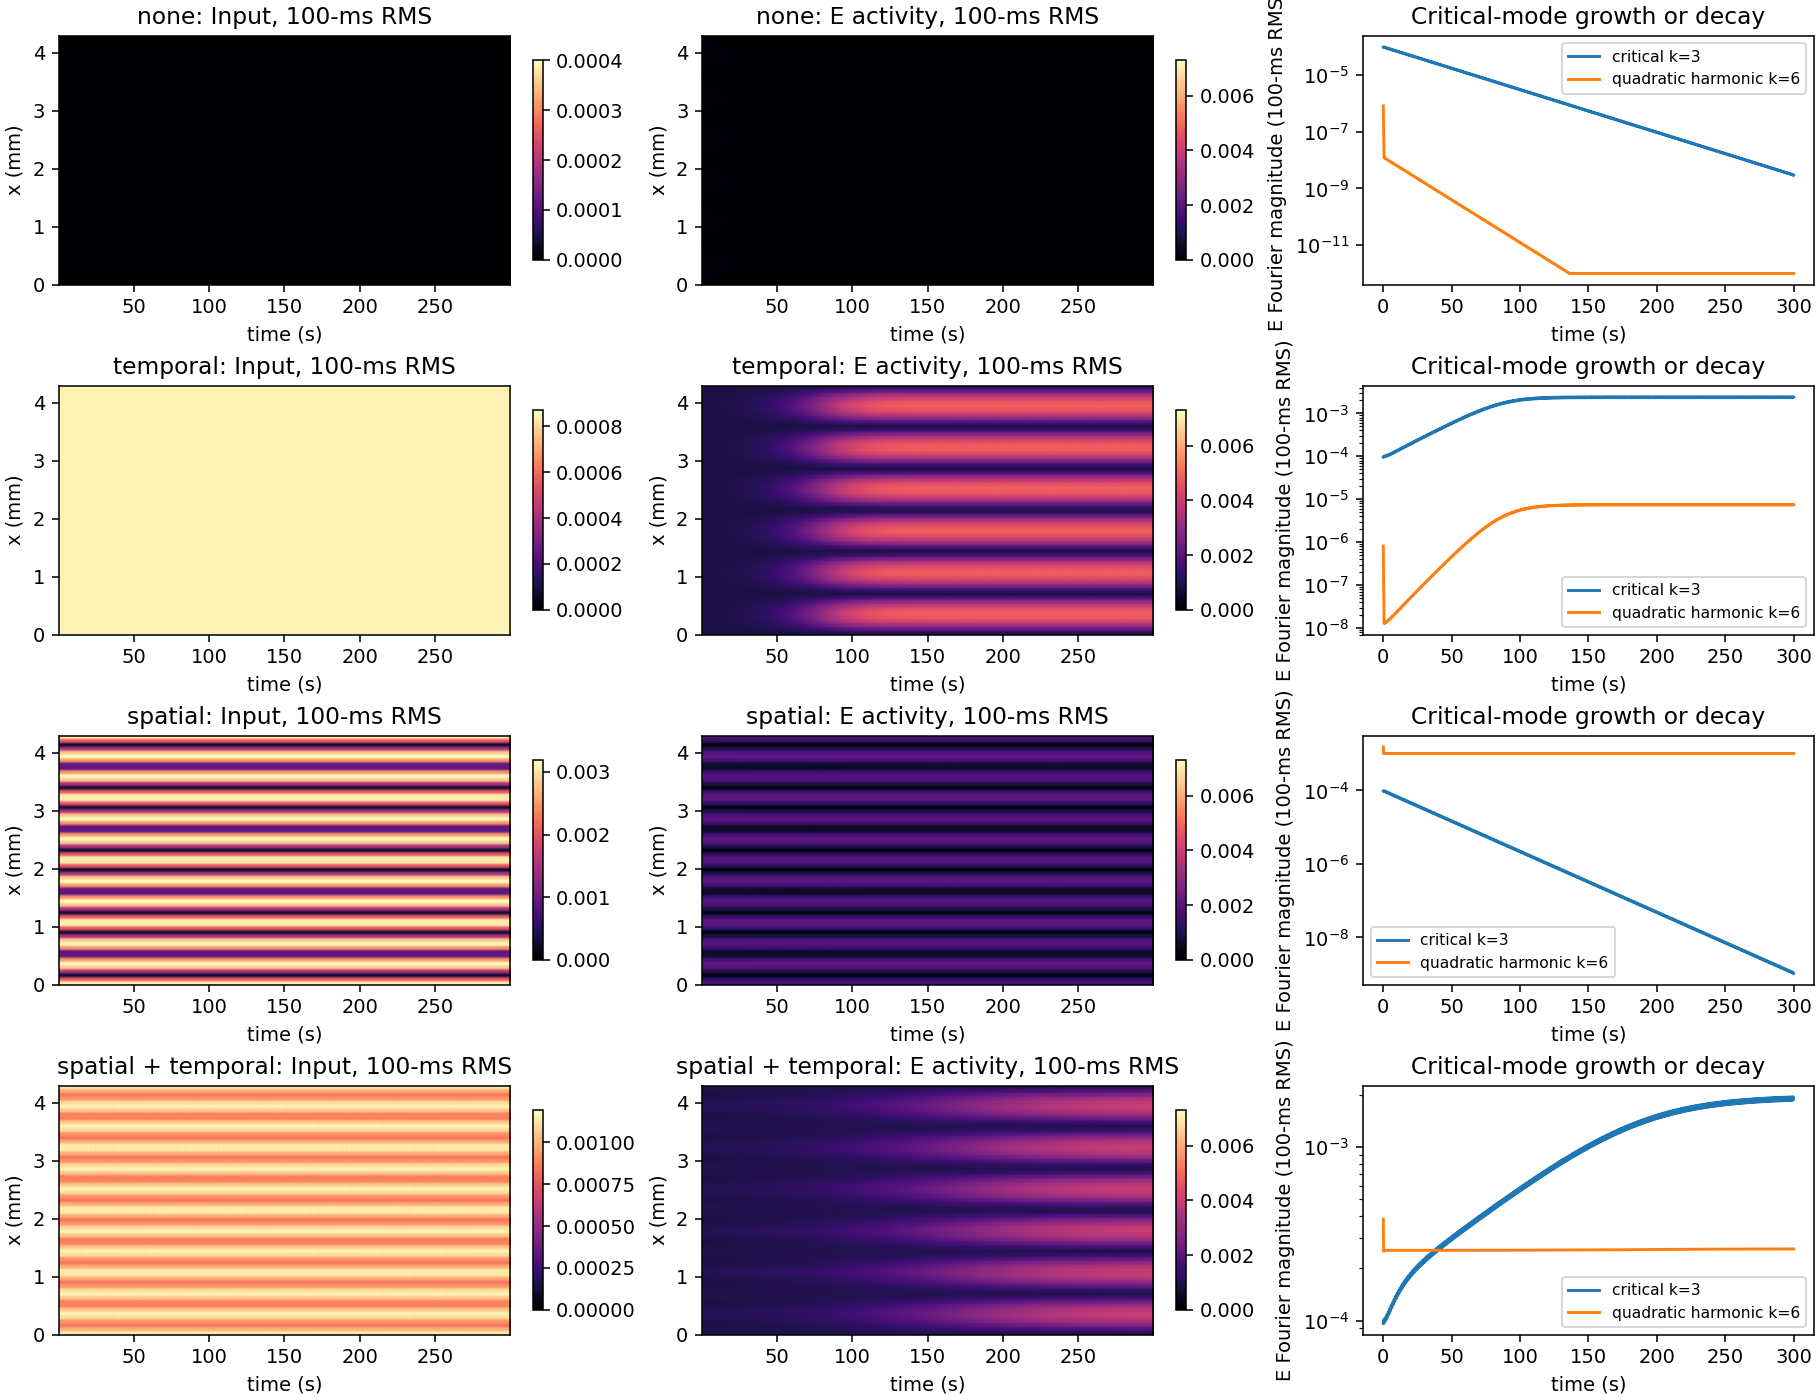

  none                 late critical amplitude 7.548e-09, critical-mode frequency 9.53 Hz
  temporal             late critical amplitude 3.440e-03, critical-mode frequency 9.53 Hz
  spatial              late critical amplitude 2.903e-09, critical-mode frequency 9.50 Hz
  spatial + temporal   late critical amplitude 2.734e-03, critical-mode frequency 9.53 Hz

4 populations: direct field runs from analysis.ipynb


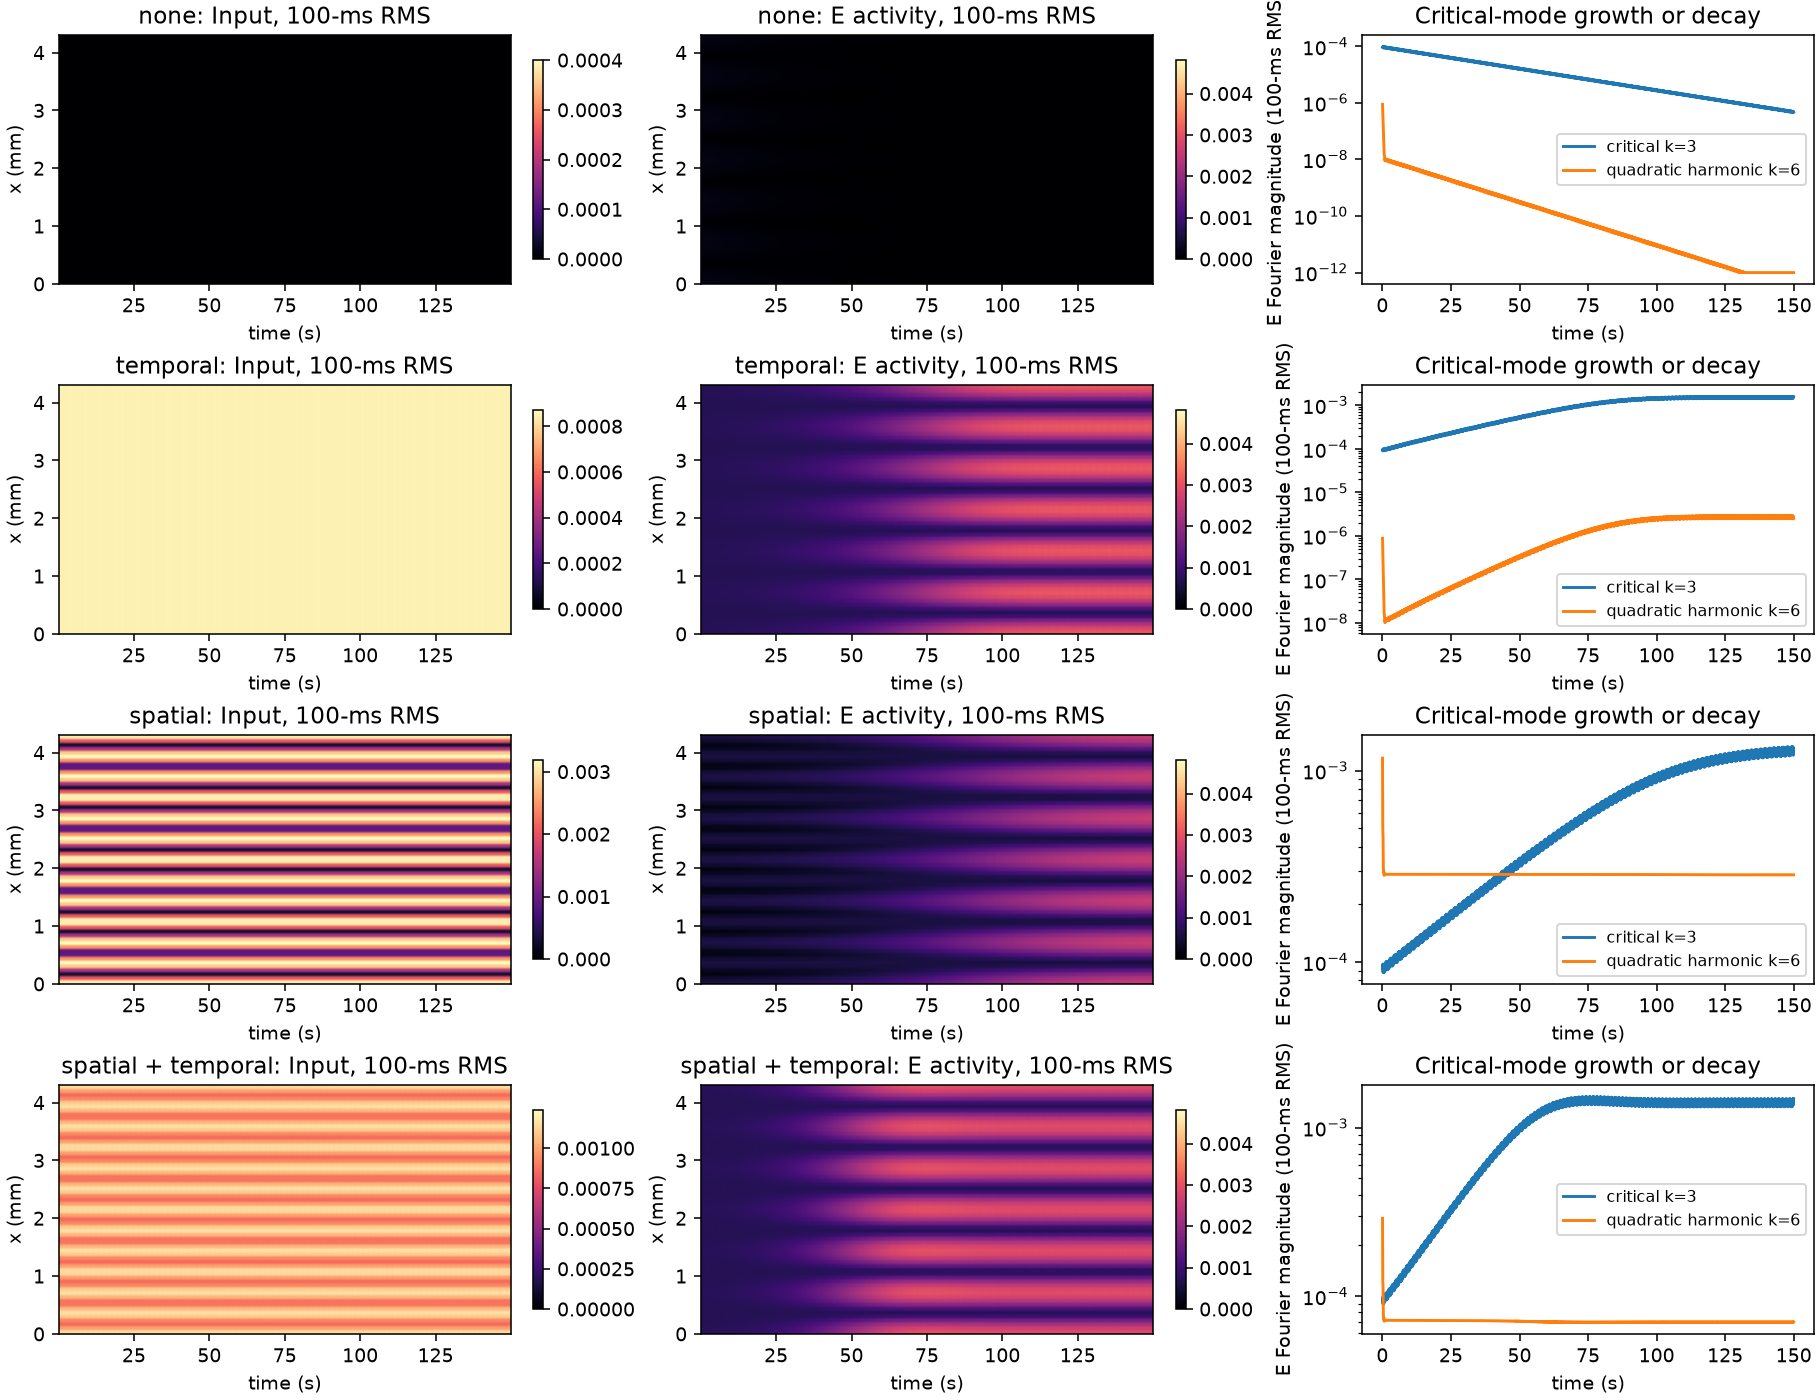

  none                 late critical amplitude 9.400e-07, critical-mode frequency 13.20 Hz
  temporal             late critical amplitude 2.256e-03, critical-mode frequency 13.20 Hz
  spatial              late critical amplitude 1.875e-03, critical-mode frequency 13.20 Hz
  spatial + temporal   late critical amplitude 2.119e-03, critical-mode frequency 13.20 Hz

Figures saved in /Users/jhpaeng306/GitHub/mcn_project/simulations/output/v1_three_four_literature


In [10]:
for K in (3, 4):
    cached = ROOT/f'simulations/output/main_literature/{K}pop_1d'
    if (cached/'forcing_comparison.png').exists():
        print(f'\n{K} populations: direct field runs from analysis.ipynb')
        display(Image(filename=str(cached/'forcing_comparison.png')))
        summary = json.loads((cached/'summary.json').read_text())
        for label in ['none', 'temporal', 'spatial', 'spatial + temporal']:
            c = summary['cases'].get(label, {})
            print(f"  {label:20s} late critical amplitude {c.get('critical_late', float('nan')):.3e}, "
                  f"critical-mode frequency {c.get('mode_frequency_hz', float('nan')):.2f} Hz")
    else:
        print('Run analysis.ipynb first to create', cached)
print('\nFigures saved in', OUT)